Kalp ve damar hastalıkları dünya genelinde ölüm nedenlerinin başında gelmekte olup, yüksek riskli hastaların erken teşhisi hayat kurtarıcıdır. Bu projede hastaların demografik bilgileri ve rutin klinik ölçüm sonuçları (yaş, cinsiyet, göğüs ağrısı tipi, kan basıncı, kolesterol, EKG verileri vb.) girdi olarak kullanılarak, bireyin kalp yetmezliği/kalp hastalığı riski taşıyıp taşımadığını (0: Normal, 1: Kalp Hastalığı) ikili sınıflandırma (binary classification) ile tahmin eden bir Derin Öğrenme (Multi-Layer Perceptron - MLP) modeli geliştirilecektir. Amaç, hekimlere erken tanı süreçlerinde yüksek duyarlılığa (Recall) sahip bir klinik karar destek aracı sunmaktır.

Bu çalışmada, kalp hastalığının tahmin edilmesine yönelik derin öğrenme tabanlı bir ikili sınıflandırma modeli geliştirmek amacıyla Kaggle platformunda fedesoriano tarafından yayımlanan *Heart Failure Prediction Dataset* kullanılmıştır.

Veri seti toplam 12 sütundan oluşmaktadır. Bu sütunların 11'i bağımsız değişken, 1'i ise bağımlı değişkendir. Bağımsız değişkenler hastaların yaş, cinsiyet, göğüs ağrısı türü, dinlenme kan basıncı, kolesterol seviyesi, açlık kan şekeri, elektrokardiyografi sonuçları, maksimum kalp hızı, egzersize bağlı anjina, ST segment depresyonu ve ST segment eğimi gibi demografik ve klinik özelliklerini içermektedir.

Bağımlı değişken olan `HeartDisease`, hastanın kalp hastalığı durumunu temsil etmektedir. Bu değişkende 0 değeri kalp hastalığının bulunmadığını, 1 değeri ise kalp hastalığının bulunduğunu ifade etmektedir.

Çalışmanın temel amacı, hastalara ait klinik ve demografik özelliklerden yararlanarak kalp hastalığı sınıfını tahmin edebilen bir derin öğrenme modeli geliştirmek ve modelin özellikle hastalığı bulunan bireyleri doğru tespit etme başarısını Recall metriği üzerinden değerlendirmektir.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.metrics import Recall, Precision, AUC
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt



In [ ]:
# KAGGLE VERİ SETİNİ İNDİRELİM
path = kagglehub.dataset_download(
    "fedesoriano/heart-failure-prediction"
)

# İNDİRİLEN CSV DOSYASINI OKUYALIM
df = pd.read_csv(path + "/heart.csv")

print("Veri seti başarıyla indirildi!")
print("Dosya konumu:", path)

Using Colab cache for faster access to the 'heart-failure-prediction' dataset.
Veri seti başarıyla indirildi!
Dosya konumu: /kaggle/input/heart-failure-prediction


In [ ]:
# VERİ SETİNİN İLK 10 SATIRINI GÖSTERELİM

display(df.head(10))

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0
5,39,M,NAP,120,339,0,Normal,170,N,0.0,Up,0
6,45,F,ATA,130,237,0,Normal,170,N,0.0,Up,0
7,54,M,ATA,110,208,0,Normal,142,N,0.0,Up,0
8,37,M,ASY,140,207,0,Normal,130,Y,1.5,Flat,1
9,48,F,ATA,120,284,0,Normal,120,N,0.0,Up,0


In [ ]:
print("Veri seti boyutu:", df.shape)

Veri seti boyutu: (918, 12)


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


In [ ]:
# Hastalık durumuna göre sayısal değer açıklaması
# SAYISAL DEĞİŞKENLERİ SEÇ
numeric_columns = [
    "Age",
    "RestingBP",
    "Cholesterol",
    "MaxHR",
    "Oldpeak"
]

# HASTALIK DURUMUNA GÖRE ORTALAMALARI HESAPLA
df.groupby("HeartDisease")[numeric_columns].mean().round(2)

,Age,RestingBP,Cholesterol,MaxHR,Oldpeak
HeartDisease,,,,,
0,50.55,130.18,238.77,148.15,0.41
1,55.90,134.45,251.06,127.66,1.27


AgeGroup
30 altı     0.00
30-40      36.36
40-50      41.70
50-60      58.27
60-70      73.60
70 üstü    66.67
Name: HeartDisease, dtype: float64


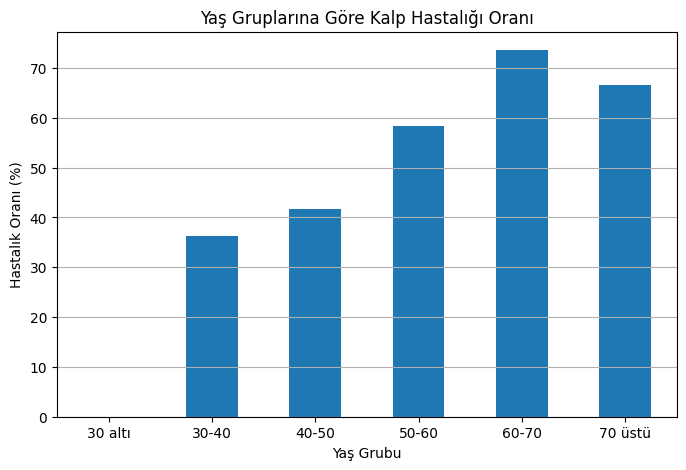

In [ ]:
# Yaş arttıkça hastalık oranı değişiyor mu?
# YAŞ GRUPLARI OLUŞTUR
df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[0, 30, 40, 50, 60, 70, 100],
    labels=["30 altı", "30-40", "40-50", "50-60", "60-70", "70 üstü"]
)

# YAŞ GRUPLARINA GÖRE HASTALIK ORANI
age_rate = df.groupby("AgeGroup", observed=False)["HeartDisease"].mean() * 100

print(age_rate.round(2))
age_rate.plot(kind="bar", figsize=(8, 5))

plt.title("Yaş Gruplarına Göre Kalp Hastalığı Oranı")
plt.xlabel("Yaş Grubu")
plt.ylabel("Hastalık Oranı (%)")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

In [ ]:
#Göğüs ağrısına göre hastalık oranı
chest_pain_rate = (
    df.groupby("ChestPainType")["HeartDisease"]
    .mean() * 100
)

print(chest_pain_rate.sort_values(ascending=False).round(2))

ChestPainType
ASY    79.03
TA     43.48
NAP    35.47
ATA    13.87
Name: HeartDisease, dtype: float64


In [ ]:
# Egzersiz sırasında göğüs ağrısı ile hastalık ilişkisi
exercise_rate = (
    df.groupby("ExerciseAngina")["HeartDisease"]
    .mean() * 100
)

print(exercise_rate.round(2))

ExerciseAngina
N    35.10
Y    85.18
Name: HeartDisease, dtype: float64


In [ ]:
# EKSİK (NULL) VE SIFIR DEĞERLERİNİ HESAPLAYALIM

analysis = pd.DataFrame({
    "Null Sayısı": df.isnull().sum(),
    "Null Oranı (%)": (df.isnull().sum() / len(df)) * 100,
    "Sıfır Sayısı": (df == 0).sum(),
    "Sıfır Oranı (%)": ((df == 0).sum() / len(df)) * 100
})

display(analysis.round(2))

,Null Sayısı,Null Oranı (%),Sıfır Sayısı,Sıfır Oranı (%)
Age,0,0.0,0,0.00
Sex,0,0.0,0,0.00
ChestPainType,0,0.0,0,0.00
RestingBP,0,0.0,1,0.11
Cholesterol,0,0.0,172,18.74
FastingBS,0,0.0,704,76.69
RestingECG,0,0.0,0,0.00
MaxHR,0,0.0,0,0.00
ExerciseAngina,0,0.0,0,0.00
Oldpeak,0,0.0,368,40.09


Eksik ve Sıfır Değer Analizi

Veri setinin veri kalitesini değerlendirmek amacıyla eksik (Null) ve sıfır (0) değer analizleri gerçekleştirilmiştir. Bu kapsamda Pandas kütüphanesinin `isnull()` fonksiyonu kullanılarak eksik değer sayıları, karşılaştırma işlemleri kullanılarak ise her sütundaki sıfır değerlerinin sayıları belirlenmiştir.

Eksik değerler ile sıfır değerleri birbirinden ayrı değerlendirilmiştir. Çünkü sıfır, veri setindeki bazı değişkenler için geçerli bir kategorik veya sayısal değeri temsil etmektedir. Özellikle hedef değişken olan `HeartDisease` ve ikili yapıya sahip `FastingBS` sütunlarında sıfır değerleri anlamlıdır.

Buna karşılık yaş, dinlenme kan basıncı ve maksimum kalp hızı gibi değişkenlerde sıfır değerlerinin bulunması veri kalitesi açısından ayrıca incelenmesi gereken bir durumdur. Bu nedenle sıfır değerleri doğrudan eksik veri olarak kabul edilmemiş, değişkenlerin klinik anlamları dikkate alınarak değerlendirilmesi planlanmıştır.

In [ ]:

# RESTINGBP DEĞERİ SIFIR OLAN KAYDI İNCELEYELİM

display(df[df["RestingBP"] == 0])

# CHOLESTEROL DEĞERİ SIFIR OLAN KAYITLARI İNCELEYELİM

display(df[df["Cholesterol"] == 0].head(10))

# BU KAYITLARIN HEDEF DEĞİŞKEN DAĞILIMINI İNCELEYELİM

print("Cholesterol sıfır olan kayıtların sınıf dağılımı:")
print(df[df["Cholesterol"] == 0]["HeartDisease"].value_counts())

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
449,55,M,NAP,0,0,0,Normal,155,N,1.5,Flat,1


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
293,65,M,ASY,115,0,0,Normal,93,Y,0.0,Flat,1
294,32,M,TA,95,0,1,Normal,127,N,0.7,Up,1
295,61,M,ASY,105,0,1,Normal,110,Y,1.5,Up,1
296,50,M,ASY,145,0,1,Normal,139,Y,0.7,Flat,1
297,57,M,ASY,110,0,1,ST,131,Y,1.4,Up,1
298,51,M,ASY,110,0,1,Normal,92,N,0.0,Flat,1
299,47,M,ASY,110,0,1,ST,149,N,2.1,Up,1
300,60,M,ASY,160,0,1,Normal,149,N,0.4,Flat,1
301,55,M,ATA,140,0,0,ST,150,N,0.2,Up,0
302,53,M,ASY,125,0,1,Normal,120,N,1.5,Up,1


Cholesterol sıfır olan kayıtların sınıf dağılımı:
HeartDisease
1    152
0     20
Name: count, dtype: int64


Cholesterol Değişkenindeki Sıfır Değerlerin Değerlendirilmesi

Veri setinde yapılan incelemeler sonucunda Cholesterol değişkeninde 172 adet sıfır değer tespit edilmiştir. Bu değerler toplam gözlemlerin yaklaşık %18,74'ünü oluşturmaktadır.

Kolesterol konsantrasyonunun klinik olarak sıfır olması beklenmediğinden, söz konusu değerler gerçek ölçüm sonuçları olarak değerlendirilmemiş ve eksik ölçüm adayı olarak ele alınmıştır.

Sıfır kolesterol değerine sahip gözlemlerin hedef değişkene göre dağılımı incelendiğinde, 152 gözlemin kalp hastalığı bulunan, 20 gözlemin ise kalp hastalığı bulunmayan sınıfta yer aldığı görülmüştür.

Bu bulgular doğrultusunda sıfır değerlerin doğrudan silinmesi yerine uygun bir eksik veri tamamlama yönteminin kullanılması planlanmıştır. Ortalama ve medyan yöntemleri değerlendirilerek, değişkenin dağılım özelliklerine ve aykırı değer durumuna uygun yöntemin seçilmesi hedeflenmektedir.

Ortalama: 244.6353887399464
Medyan: 237.0
Standart Sapma: 59.15352367700275
Minimum: 85
Maksimum: 603
Çarpıklık: 1.238534436848176


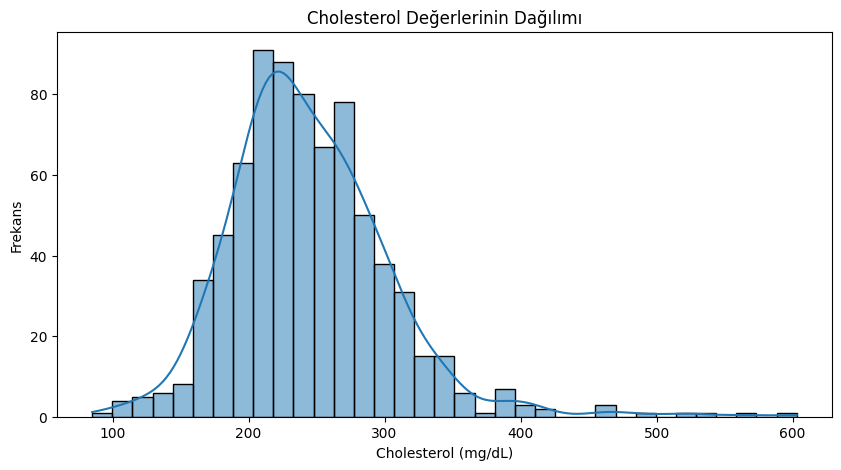

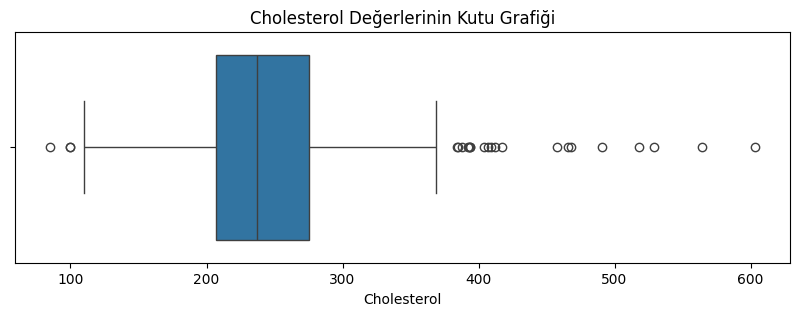

In [ ]:
# SIFIR OLMAYAN KOLESTEROL DEĞERLERİNİ İNCELEYELİM

cholesterol_valid = df.loc[df["Cholesterol"] != 0, "Cholesterol"]

# TANIMLAYICI İSTATİSTİKLER
print("Ortalama:", cholesterol_valid.mean())
print("Medyan:", cholesterol_valid.median())
print("Standart Sapma:", cholesterol_valid.std())
print("Minimum:", cholesterol_valid.min())
print("Maksimum:", cholesterol_valid.max())
print("Çarpıklık:", cholesterol_valid.skew())

# DAĞILIM GRAFİĞİ
plt.figure(figsize=(10, 5))
sns.histplot(cholesterol_valid, kde=True)
plt.title("Cholesterol Değerlerinin Dağılımı")
plt.xlabel("Cholesterol (mg/dL)")
plt.ylabel("Frekans")
plt.show()

# KUTU GRAFİĞİ
plt.figure(figsize=(10, 3))
sns.boxplot(x=cholesterol_valid)
plt.title("Cholesterol Değerlerinin Kutu Grafiği")
plt.show()

Sıfır olmayan kolesterol değerleri üzerinde gerçekleştirilen istatistiksel incelemede ortalama 244,64, medyan 237, standart sapma 59,15, minimum değer 85 ve maksimum değer 603 olarak hesaplanmıştır. Dağılımın çarpıklık katsayısı 1,24'tür. Pozitif çarpıklık, dağılımın sağ kuyruğunun daha uzun olduğunu ve yüksek uç değerlerin bulunduğunu göstermektedir.

Ortalamanın uç değerlerden etkilenebilmesi, medyanın ise bu değerlere karşı daha dayanıklı olması nedeniyle eksik kolesterol ölçümlerinin medyan yöntemiyle tamamlanması uygun görülmüştür. Bu doğrultuda kullanılacak medyan değeri 237 olarak belirlenmiştir. Veri sızıntısını önlemek amacıyla bu değer, modelleme aşamasında yalnızca eğitim verisi üzerinden hesaplanacak ve test verisine de aynı değer uygulanacaktır.

Ortalama: 132.54089422028352
Medyan: 130.0
Standart Sapma: 17.99974879939768
Minimum: 80
Maksimum: 200
Çarpıklık: 0.6071947160162691


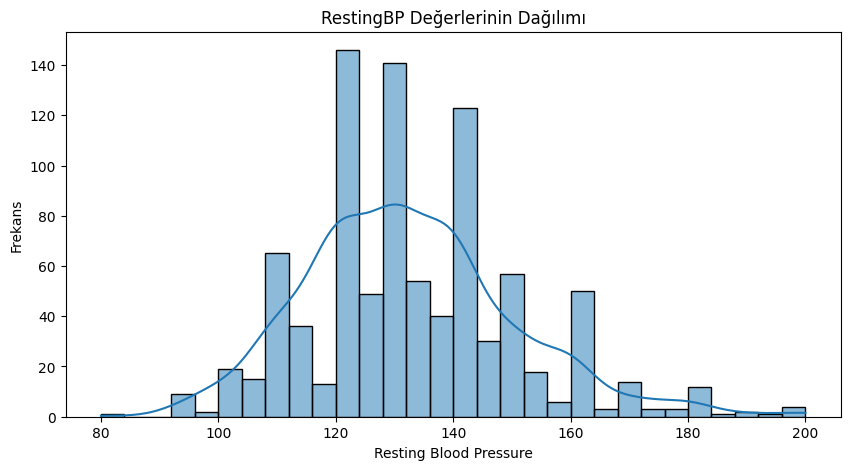

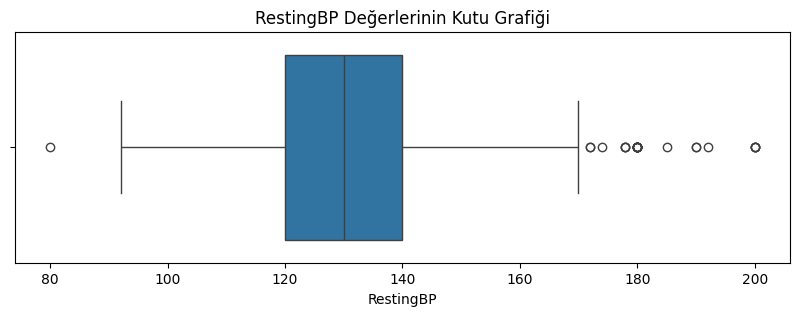

In [ ]:
# SIFIR OLMAYAN TANSİYON DEĞERLERİNİ SEÇELİM
restingbp_valid = df.loc[df["RestingBP"] != 0, "RestingBP"]

# TANIMLAYICI İSTATİSTİKLER
print("Ortalama:", restingbp_valid.mean())
print("Medyan:", restingbp_valid.median())
print("Standart Sapma:", restingbp_valid.std())
print("Minimum:", restingbp_valid.min())
print("Maksimum:", restingbp_valid.max())
print("Çarpıklık:", restingbp_valid.skew())

# DAĞILIM GRAFİĞİ
plt.figure(figsize=(10, 5))
sns.histplot(restingbp_valid, kde=True)
plt.title("RestingBP Değerlerinin Dağılımı")
plt.xlabel("Resting Blood Pressure")
plt.ylabel("Frekans")
plt.show()

# KUTU GRAFİĞİ
plt.figure(figsize=(10, 3))
sns.boxplot(x=restingbp_valid)
plt.title("RestingBP Değerlerinin Kutu Grafiği")
plt.show()

Cholesterol değişkeninde 172 adet sıfır değer (%18,74), RestingBP değişkeninde ise 1 adet sıfır değer (%0,11) tespit edilmiştir. Her iki değişkende de sıfır değerler fizyolojik ölçüm açısından geçerli kabul edilemeyeceğinden eksik ölçüm adayı olarak değerlendirilmiştir.

Eksik ölçüm olarak değerlendirilen sıfır değerler silinmek yerine medyan ile tamamlanacaktır. Veri sızıntısını önlemek amacıyla medyan değerleri yalnızca eğitim verisi üzerinden hesaplanacak ve aynı değerler test verisine uygulanacaktır.

In [ ]:
# GECERSIZ SIFIR DEGERLERI EKSIK VERI OLARAK ISARETLE
df["Cholesterol"] = df["Cholesterol"].replace(0, np.nan)
df["RestingBP"] = df["RestingBP"].replace(0, np.nan)

# YENI EKSIK VERI DURUMUNU KONTROL ET
print(df[["Cholesterol", "RestingBP"]].isnull().sum())

Cholesterol    172
RestingBP        1
dtype: int64


In [ ]:
# HEDEF DEGISKENI AYIR
X = df.drop("HeartDisease", axis=1)
y = df["HeartDisease"]

In [ ]:
# ILK OLARAK TEST VERISINI AYIR
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y,
    test_size=0.15,
    random_state=42,
    stratify=y
)

# KALAN VERIDEN VALIDATION KUMESINI AYIR
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val,
    test_size=0.15 / 0.85,
    random_state=42,
    stratify=y_train_val
)

# VERI SETLERININ BOYUTLARINI KONTROL ET
print("Eğitim:", X_train.shape)
print("Doğrulama:", X_val.shape)
print("Test:", X_test.shape)

Eğitim: (642, 11)
Doğrulama: (138, 11)
Test: (138, 11)


In [ ]:
# SAYISAL DEGISKENLERI BELIRLE
numeric_cols = X_train.select_dtypes(include=np.number).columns

# MEDYAN ILE DOLDURMA NESNESINI OLUSTUR
imputer = SimpleImputer(strategy="median")

# MEDYANI YALNIZCA EGITIM VERISINDEN HESAPLA
X_train[numeric_cols] = imputer.fit_transform(X_train[numeric_cols])

# AYNI MEDYANLARI VALIDATION VE TEST VERISINE UYGULA
X_val[numeric_cols] = imputer.transform(X_val[numeric_cols])
X_test[numeric_cols] = imputer.transform(X_test[numeric_cols])

In [ ]:
# UC VERI KUMESINDEKI EKSIK DEGERLERI KONTROL ET
print("Eğitim eksik değer sayısı:", X_train.isnull().sum().sum())
print("Doğrulama eksik değer sayısı:", X_val.isnull().sum().sum())
print("Test eksik değer sayısı:", X_test.isnull().sum().sum())

Eğitim eksik değer sayısı: 0
Doğrulama eksik değer sayısı: 0
Test eksik değer sayısı: 0


Verinin Eğitim, Doğrulama ve Test Kümelerine Ayrılması

Modelin genelleme performansını değerlendirmek ve aşırı öğrenme (overfitting) riskini takip etmek amacıyla veri seti üç ayrı kümeye bölünmüştür. Veri setinin %70'i eğitim, %15'i doğrulama ve %15'i test amacıyla ayrılmıştır.

Veri ayrıştırma işleminde stratify parametresi kullanılarak hedef değişkenin sınıf dağılımının kümeler arasında korunması amaçlanmıştır. İşlem sırasında tekrarlanabilir sonuçlar elde etmek için random_state=42 değeri belirlenmiştir.

Eksik Verilerin Medyan ile Doldurulması

Cholesterol ve RestingBP değişkenlerinde eksik ölçüm olarak işaretlenen sıfır değerler, medyan yöntemiyle tamamlanmıştır. Veri sızıntısını önlemek amacıyla medyan değerleri yalnızca eğitim kümesinden hesaplanmış; hesaplanan değerler doğrulama ve test kümelerine de uygulanmıştır.

Bu işlemde Scikit-learn kütüphanesinin SimpleImputer sınıfından yararlanılmıştır. Böylece tüm veri kümelerinde aynı imputasyon değerleri kullanılarak model değerlendirme sürecinin tutarlılığı korunmuştur.

,Kisi Sayisi,Oran (%)
HeartDisease,,
0,286,44.55
1,356,55.45


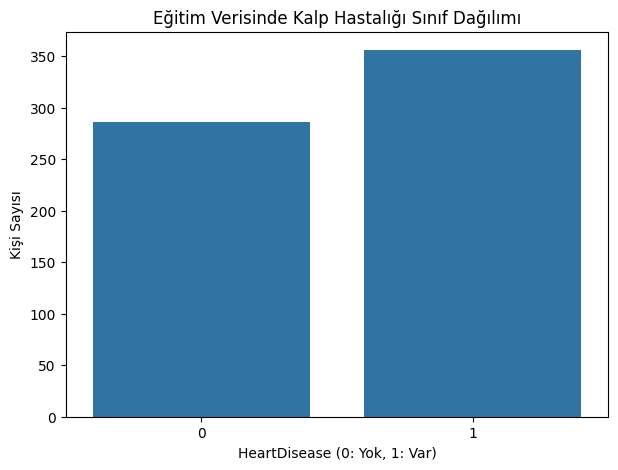

In [ ]:
# EGITIM VERISINDEKI SINIF SAYILARINI HESAPLA
class_counts = y_train.value_counts().sort_index()

# SINIFLARIN YUZDELIK DAGILIMINI HESAPLA
class_percentages = y_train.value_counts(normalize=True).sort_index() * 100

# SONUCLARI TABLO HALINDE GOSTER
distribution = pd.DataFrame({
    "Kisi Sayisi": class_counts,
    "Oran (%)": class_percentages
})

display(distribution.round(2))
# SINIF DAGILIMINI GORSELLESTIR
plt.figure(figsize=(7, 5))

sns.countplot(x=y_train)

plt.title("Eğitim Verisinde Kalp Hastalığı Sınıf Dağılımı")
plt.xlabel("HeartDisease (0: Yok, 1: Var)")
plt.ylabel("Kişi Sayısı")

plt.show()

In [ ]:
# SINIFLAR ARASINDAKI DENGESIZLIK ORANINI HESAPLA
imbalance_ratio = class_counts.max() / class_counts.min()

print("Dengesizlik Oranı:", round(imbalance_ratio, 2))

Dengesizlik Oranı: 1.24


Eğitim Verisinde Sınıf Dağılımının İncelenmesi

Model eğitimi öncesinde hedef değişken olan HeartDisease'in eğitim kümesindeki sınıf dağılımı incelenmiştir. Bu analiz ile kalp hastalığı bulunmayan (0) ve bulunan (1) bireylerin sayıları ve yüzdelik oranları değerlendirilmiştir.

Sınıf dağılımının incelenmesindeki temel amaç, veri setinde sınıf dengesizliği bulunup bulunmadığını belirlemek ve model değerlendirme sürecinde doğruluk (Accuracy) metriğinin yanı sıra Recall ve F1-score gibi metriklerin önemini değerlendirmektir.

Eğitim verisindeki hedef değişkenin sınıf dağılımı incelenmiş ve dengesizlik oranı 1,24 olarak hesaplanmıştır. Bu değer, çoğunluk sınıfındaki örnek sayısının azınlık sınıfındaki örnek sayısına oranının düşük olduğunu göstermektedir.

Sınıflar arasında belirgin bir dengesizlik bulunmadığı değerlendirildiğinden SMOTE, aşırı örnekleme veya eksik örnekleme gibi dengeleme yöntemlerinin başlangıç aşamasında uygulanmasına gerek duyulmamıştır. Model, mevcut sınıf dağılımı kullanılarak eğitilecektir.

In [ ]:
# SAYISAL VE KATEGORIK SUTUNLARI BELIRLE
numeric_cols = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X_train.select_dtypes(exclude=np.number).columns.tolist()

print("Sayısal değişkenler:", numeric_cols)
print("Kategorik değişkenler:", categorical_cols)

Sayısal değişkenler: ['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak']
Kategorik değişkenler: ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']


In [ ]:
# SAYISAL VE KATEGORIK DONUSUMLERI TANIMLA
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_cols)
    ]
)

# DONUSUMU EGITIM VERISINDE OGREN VE UYGULA
X_train_processed = preprocessor.fit_transform(X_train)

# AYNI DONUSUMLERI DIGER VERI KUMELERINE UYGULA
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

In [ ]:
# DONUSUM SONRASI VERI BOYUTLARINI KONTROL ET
print("Eğitim verisi:", X_train_processed.shape)
print("Doğrulama verisi:", X_val_processed.shape)
print("Test verisi:", X_test_processed.shape)

# SAYISAL OZELLIKLERIN ORTALAMA VE STANDART SAPMASINI KONTROL ET
print("\nEğitim verisindeki dönüştürülmüş sayısal özelliklerin ortalamaları:")
print(X_train_processed[:, :len(numeric_cols)].mean(axis=0).round(3))

print("\nEğitim verisindeki dönüştürülmüş sayısal özelliklerin standart sapmaları:")
print(X_train_processed[:, :len(numeric_cols)].std(axis=0).round(3))

Eğitim verisi: (642, 20)
Doğrulama verisi: (138, 20)
Test verisi: (138, 20)

Eğitim verisindeki dönüştürülmüş sayısal özelliklerin ortalamaları:
[-0.  0.  0.  0.  0.  0.]

Eğitim verisindeki dönüştürülmüş sayısal özelliklerin standart sapmaları:
[1. 1. 1. 1. 1. 1.]


Kategorik Değişkenlerin Kodlanması ve Sayısal Değişkenlerin Ölçeklendirilmesi

Derin öğrenme modelinin giriş verilerini işleyebilmesi amacıyla kategorik değişkenlere One-Hot Encoding yöntemi uygulanmıştır. Bu yöntemle kategorik değerler, her kategori için ayrı ikili (0/1) özellik sütunlarına dönüştürülmüştür.

Sayısal değişkenlerin farklı ölçüm aralıklarında bulunmasından kaynaklanabilecek ölçek farklılıklarını azaltmak amacıyla StandardScaler kullanılmıştır. Bu yöntem, sayısal özellikleri ortalaması sıfır ve standart sapması bir olacak şekilde standartlaştırmıştır.

Veri sızıntısını önlemek amacıyla kodlama ve ölçeklendirme işlemlerinin öğrenme aşaması yalnızca eğitim kümesinde gerçekleştirilmiş; doğrulama ve test kümelerine aynı dönüşümler uygulanmıştır.

Kategorik Değişkenlerin Kodlanması ve Sayısal Değişkenlerin Ölçeklendirilmesi

Veri ön işleme aşamasında başlangıçta 11 giriş özelliği bulunan veri setine kategorik değişkenler için One-Hot Encoding, sayısal değişkenler için StandardScaler uygulanmıştır. Kodlama işlemi sonucunda modelin kullanacağı özellik sayısı 20'ye yükselmiştir.

Dönüşüm sonrasında veri seti 642 eğitim, 138 doğrulama ve 138 test gözleminden oluşacak şekilde düzenlenmiştir. Eğitim verisindeki standartlaştırılmış sayısal özelliklerin ortalamaları yaklaşık sıfır, standart sapmaları ise bir olarak hesaplanmıştır.

Dönüşüm parametreleri yalnızca eğitim verisi kullanılarak öğrenilmiş, doğrulama ve test verilerine aynı parametreler uygulanmıştır. Böylece modelin değerlendirme sürecinde veri sızıntısı önlenmiştir.

Model Seçimi ve Tercih Nedeni

Bu çalışmada kalp hastalığı sınıflandırması için Derin Öğrenme yöntemlerinden Çok Katmanlı Algılayıcı (Multi-Layer Perceptron - MLP) modeli tercih edilmiştir.

Çalışmanın temel amacı yalnızca yüksek doğruluk elde etmek değil, kalp hastalığı bulunan bireylerin doğru tespit edilme oranını da artırmaktır. Bu nedenle model değerlendirmesinde Accuracy metriğinin yanında özellikle Recall, Precision, F1-score ve Confusion Matrix değerleri dikkate alınacaktır.

Bu gerekçeler doğrultusunda MLP modeli, çalışmanın başlangıç derin öğrenme mimarisi olarak seçilmiştir. Modelin başarısı doğrulama ve test verileri üzerinde gerçekleştirilecek deneylerle değerlendirilecektir.

In [ ]:
# TEKRARLANABILIRLIK ICIN RANDOM SEED BELIRLE
tf.keras.utils.set_random_seed(42)
# MLP MODELINI OLUSTUR
model = Sequential([
    Input(shape=(20,)),

    Dense(64, activation="relu"),
    Dense(32, activation="relu"),

    Dense(1, activation="sigmoid")
])

# MODEL MIMARISINI GOSTER
model.summary()
# MODELI DERLE
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        Recall(name="recall"),
        Precision(name="precision"),
        AUC(name="auc")
    ]
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,457 (13.50 KB)

 Trainable params: 3,457 (13.50 KB)

 Non-trainable params: 0 (0.00 B)

MLP Modelinin Oluşturulması ve Derlenmesi

TensorFlow ve Keras kütüphaneleri kullanılarak Çok Katmanlı Algılayıcı (MLP) mimarisi oluşturulmuştur.

Modelin giriş katmanı 20 özellikten oluşmaktadır. İlk gizli katmanda 64, ikinci gizli katmanda ise 32 nöron kullanılmış ve her iki katmanda ReLU aktivasyon fonksiyonu tercih edilmiştir. İkili sınıflandırma gerçekleştiren çıkış katmanında tek nöron ve Sigmoid aktivasyon fonksiyonu kullanılmıştır.

Model özeti incelendiğinde toplam 3.457 eğitilebilir parametre bulunduğu görülmüştür. Modelde eğitilebilir olmayan parametre bulunmamaktadır.

Optimizasyon algoritması olarak Adam, başlangıç öğrenme oranı olarak 0.001 ve kayıp fonksiyonu olarak Binary Crossentropy belirlenmiştir. Performans değerlendirmesinde Accuracy, Recall, Precision ve AUC metrikleri kullanılmıştır.

In [ ]:
# ERKEN DURDURMA MEKANIZMASINI OLUSTUR
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True
)

# MODELI EGIT
history = model.fit(
    X_train_processed,
    y_train,
    validation_data=(X_val_processed, y_val),
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/100
21/21 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - accuracy: 0.7430 - auc: 0.8119 - loss: 0.6095 - precision: 0.7574 - recall: 0.7893 - val_accuracy: 0.8261 - val_auc: 0.8891 - val_loss: 0.5245 - val_precision: 0.8514 - val_recall: 0.8289
Epoch 2/100
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8380 - auc: 0.9125 - loss: 0.4612 - precision: 0.8351 - recall: 0.8820 - val_accuracy: 0.8261 - val_auc: 0.9015 - val_loss: 0.4259 - val_precision: 0.8333 - val_recall: 0.8553
Epoch 3/100
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8442 - auc: 0.9212 - loss: 0.3759 - precision: 0.8368 - recall: 0.8933 - val_accuracy: 0.8406 - val_auc: 0.9070 - val_loss: 0.3883 - val_precision: 0.8462 - val_recall: 0.8684
Epoch 4/100
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8520 - auc: 0.9285 - loss: 0.3409 - precision: 0.8407 - recall: 0.9045 - val_accuracy: 0.8406 - val_auc: 0.9137 - val_loss: 0.3771 - val_precision: 0.8462 - val_recall: 0.8684
Epoch 5/100
21/21 ━━━━━━━━━━━━━━━━━

In [ ]:
# EN DUSUK DOGRULAMA KAYBININ OLDUGU EPOCH
best_epoch = np.argmin(history.history["val_loss"])

print("En iyi epoch:", best_epoch + 1)
print("En düşük validation loss:",
      history.history["val_loss"][best_epoch])

print("Validation accuracy:",
      history.history["val_accuracy"][best_epoch])

print("Validation recall:",
      history.history["val_recall"][best_epoch])

En iyi epoch: 23
En düşük validation loss: 0.35370010137557983
Validation accuracy: 0.8478260636329651
Validation recall: 0.8815789222717285


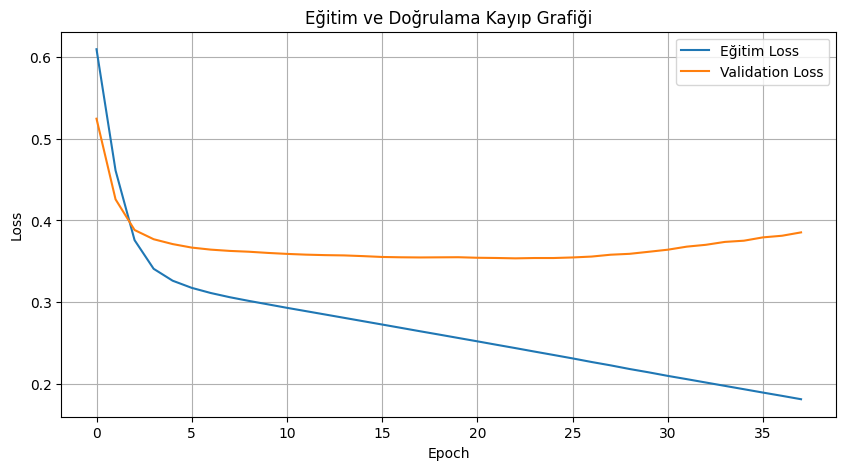

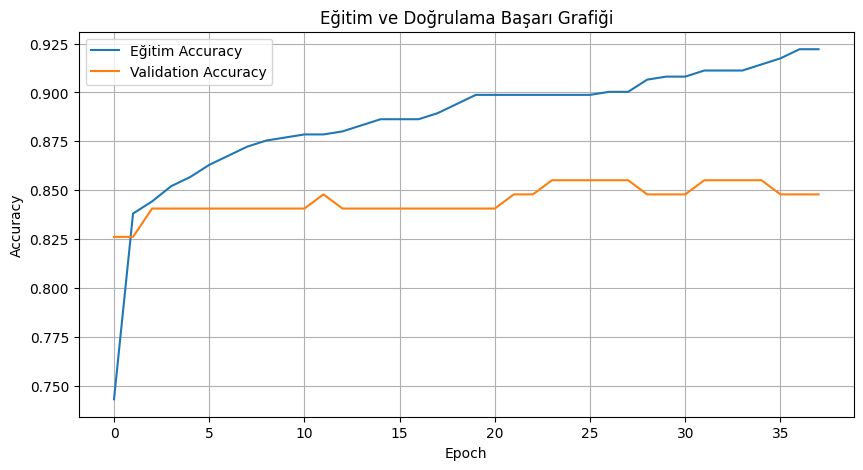

In [ ]:
# LOSS GRAFIGI
plt.figure(figsize=(10, 5))

plt.plot(history.history["loss"], label="Eğitim Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Eğitim ve Doğrulama Kayıp Grafiği")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()


# ACCURACY GRAFIGI
plt.figure(figsize=(10, 5))

plt.plot(history.history["accuracy"], label="Eğitim Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Eğitim ve Doğrulama Başarı Grafiği")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()

Eğitim ve Doğrulama Performanslarının Grafiksel Analizi

Modelin eğitim sürecindeki öğrenme davranışını değerlendirmek amacıyla eğitim ve doğrulama kayıp (Loss) ile doğruluk (Accuracy) grafikleri incelenmiştir.

Kayıp grafiğinde eğitim kaybının yaklaşık 0,61 seviyesinden 0,18 seviyesine kadar düzenli olarak azaldığı görülmüştür. Doğrulama kaybı ise başlangıçta hızlı bir düşüş göstermiş, ilerleyen epoch değerlerinde yaklaşık 0,35–0,36 aralığında yatay seyretmiştir. Yaklaşık 25. epoch sonrasında doğrulama kaybında yükseliş gözlemlenmiştir.

Doğruluk grafiğinde eğitim başarısının yaklaşık %74,5 seviyesinden %92 seviyesine yükseldiği görülmüştür. Doğrulama başarısı ise başlangıçtaki artışın ardından yaklaşık %84–%85,5 aralığında seyretmiştir.

Eğitim kaybının azalmaya devam etmesine karşın doğrulama kaybının yükselmesi ve iki kümenin doğruluk değerleri arasında fark oluşması, modelde aşırı öğrenme (overfitting) belirtisi bulunduğunu göstermektedir. Bu nedenle Early Stopping mekanizması kullanılarak doğrulama kaybının iyileşmediği durumlarda eğitimin durdurulması sağlanmıştır.

In [ ]:
# EN IYI DOGRULAMA KAYBININ BULUNDUGU EPOCH
best_epoch = np.argmin(history.history["val_loss"])

print("En iyi epoch:", best_epoch + 1)
print("Validation Loss:", history.history["val_loss"][best_epoch])
print("Validation Accuracy:", history.history["val_accuracy"][best_epoch])
print("Validation Recall:", history.history["val_recall"][best_epoch])
print("Validation Precision:", history.history["val_precision"][best_epoch])
print("Validation AUC:", history.history["val_auc"][best_epoch])

En iyi epoch: 23
Validation Loss: 0.35370010137557983
Validation Accuracy: 0.8478260636329651
Validation Recall: 0.8815789222717285
Validation Precision: 0.8481012582778931
Validation AUC: 0.928162157535553


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# VALIDATION VERISINDE OLASILIKLARI TAHMIN ET
y_val_prob = model.predict(X_val_processed).ravel()

# DENENECEK KARAR ESİKLERI
thresholds = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70]

results = []

# HER ESİK ICIN PERFORMANS HESAPLA
for threshold in thresholds:

    y_val_pred = (y_val_prob >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_val, y_val_pred),
        "Precision": precision_score(y_val, y_val_pred, zero_division=0),
        "Recall": recall_score(y_val, y_val_pred, zero_division=0),
        "F1-Score": f1_score(y_val, y_val_pred, zero_division=0)
    })

# SONUCLARI TABLODA GOSTER
threshold_results = pd.DataFrame(results)

display(threshold_results.round(4))

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step


,Threshold,Accuracy,Precision,Recall,F1-Score
0,0.30,0.8261,0.8095,0.8947,0.8500
1,0.35,0.8333,0.8193,0.8947,0.8553
2,0.40,0.8406,0.8293,0.8947,0.8608
3,0.45,0.8478,0.8395,0.8947,0.8662
4,0.50,0.8478,0.8481,0.8816,0.8645
5,0.55,0.8551,0.8590,0.8816,0.8701
6,0.60,0.8623,0.8701,0.8816,0.8758
7,0.65,0.8623,0.8904,0.8553,0.8725
8,0.70,0.8696,0.9265,0.8289,0.8750


Karar Eşiğinin Belirlenmesi

Modelin karar eşiği belirlenirken 0,30 ile 0,70 arasındaki farklı eşik değerleri karşılaştırılmıştır. Değerlendirme sonucunda 0,70 eşik değerinin doğruluk (%86,96) ve kesinlik (%92,65) açısından daha yüksek sonuç verdiği görülmüştür. Ancak bu eşikte duyarlılık (Recall) %82,89'a düşmektedir.

Bu çalışmada kalp hastalığı bulunan bireylerin mümkün olduğunca doğru tespit edilmesi önceliklendirildiğinden, %89,47 Recall değeri sağlayan 0,45 eşik değeri tercih edilmiştir. Ayrıca %83,95 Precision ve %86,62 F1-score değerleriyle duyarlılık ve kesinlik arasında dengeli bir sonuç elde edilmiştir.

Bu nedenle modelin nihai karar eşiği 0,45 olarak belirlenmiştir.

In [ ]:
# OPTIMUM KARAR ESIGI
best_threshold = 0.45

# TAHMINLERI OLUSTUR
y_val_pred = (y_val_prob >= best_threshold).astype(int)

# KARISIKLIK MATRISI
cm = confusion_matrix(y_val, y_val_pred)

print("Seçilen eşik:", best_threshold)
print("\nConfusion Matrix:")
print(cm)

print("\nSınıflandırma Raporu:")
print(classification_report(y_val, y_val_pred))

Seçilen eşik: 0.45

Confusion Matrix:
[[49 13]
 [ 8 68]]

Sınıflandırma Raporu:
              precision    recall  f1-score   support

           0       0.86      0.79      0.82        62
           1       0.84      0.89      0.87        76

    accuracy                           0.85       138
   macro avg       0.85      0.84      0.84       138
weighted avg       0.85      0.85      0.85       138



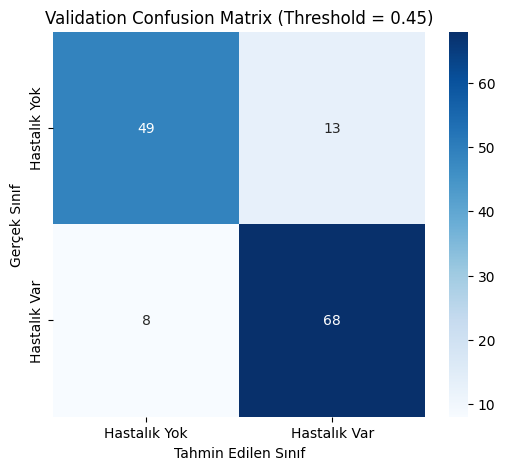

In [ ]:
# KARISIKLIK MATRISI GRAFIGI
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Hastalık Yok", "Hastalık Var"],
    yticklabels=["Hastalık Yok", "Hastalık Var"]
)

plt.title("Validation Confusion Matrix (Threshold = 0.45)")
plt.xlabel("Tahmin Edilen Sınıf")
plt.ylabel("Gerçek Sınıf")
plt.show()

In [ ]:
# TEST OLASILIK TAHMİNLERİ
y_test_prob = model.predict(X_test_processed).ravel()

# ROC-AUC HESAPLAMA
roc_auc = roc_auc_score(y_test, y_test_prob)

print("ROC-AUC:", roc_auc)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 
ROC-AUC: 0.9291171477079796


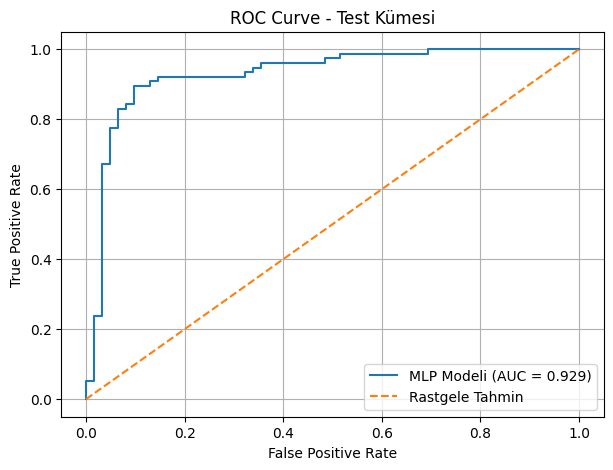

In [ ]:
# ROC EĞRİSİ İÇİN DEĞERLERİ HESAPLA
fpr, tpr, thresholds = roc_curve(y_test, y_test_prob)

# ROC EĞRİSİNİ ÇİZ
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"MLP Modeli (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Rastgele Tahmin")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Test Kümesi")
plt.legend()
plt.grid()
plt.show()

ROC Eğrisi ve Modelin Ayırt Etme Başarısı

Modelimizin kalp hastalığı bulunan ve bulunmayan kişileri ne kadar iyi ayırt edebildiğini incelemek için ROC grafiği oluşturulmuştur. Bu grafik, modelin farklı karar eşiklerinde nasıl sonuçlar verdiğini gösterir.

Grafik incelendiğinde modelin başlangıçta çok az yanlış tahmin yaparak gerçek hastaların yaklaşık %78'ini tespit edebildiği görülmektedir. Yanlış tahmin oranı biraz arttığında bu oran yaklaşık %89'a yükselmektedir. Grafik boyunca modelin gerçek hastaları yakalama başarısı artmaya devam etmekte ve belirli bir noktada hastaların tamamını tespit edebilmektedir. Ancak bu noktaya ulaşırken sağlıklı kişilerin bir kısmını da yanlışlıkla hasta olarak değerlendirmektedir.

Modelimizin genel ayırt etme başarısını gösteren AUC skoru ise 0,9291 olarak hesaplanmıştır. Bu değer, 0,50 olan rastgele tahmin seviyesinden oldukça yüksektir ve modelin iki grubu birbirinden ayırma konusunda başarılı olduğunu göstermektedir.

Sonuç olarak modelimiz, test verileri üzerinde kalp hastalığı bulunan ve bulunmayan kişileri ayırt etmede güçlü bir performans sergilemiştir.

In [ ]:
# ESIGI KONTROL ET
print("Karar esigi:", best_threshold)

# TAHMINLERI YENIDEN OLUSTUR
y_test_pred = (y_test_prob >= 0.45).astype(int)

# CONFUSION MATRIX
cm = confusion_matrix(y_test, y_test_pred)

print("\nConfusion Matrix:")
print(cm)

# YANLIS TAHMIN SAYISI
yanlis_sayisi = np.sum(np.array(y_test) != y_test_pred)

print("\nYanlis tahmin sayisi:", yanlis_sayisi)

# ACCURACY
print("Accuracy:", accuracy_score(y_test, y_test_pred))

Karar esigi: 0.45

Confusion Matrix:
[[52 10]
 [ 6 70]]

Yanlis tahmin sayisi: 16
Accuracy: 0.8840579710144928


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

print("Accuracy:", accuracy_score(y_test, y_test_pred))
print("Precision:", precision_score(y_test, y_test_pred))
print("Recall:", recall_score(y_test, y_test_pred))
print("F1-score:", f1_score(y_test, y_test_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_test_prob))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

Accuracy: 0.8840579710144928
Precision: 0.875
Recall: 0.9210526315789473
F1-score: 0.8974358974358975
ROC-AUC: 0.9291171477079796

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.84      0.87        62
           1       0.88      0.92      0.90        76

    accuracy                           0.88       138
   macro avg       0.89      0.88      0.88       138
weighted avg       0.88      0.88      0.88       138


Confusion Matrix:
[[52 10]
 [ 6 70]]


Accuracy %88,41: Model 138 kişinin 122'sini doğru sınıflandırdı.

Precision %87,50: Modelin hasta olarak tahmin ettiği kişilerin %87,5'i gerçekten hastaydı.

Recall %92,11: Gerçekte hasta olan 76 kişinin 70'ini doğru tespit etti.

F1-score %89,74: Precision ve Recall değerlerinin dengeli bir birleşimini gösteriyor.

ROC-AUC %92,91: Modelin iki sınıfı birbirinden ayırma kapasitesi yüksek.

In [ ]:
# MODELI KAYDET
model.save("kalp_hastaligi_modeli.keras")

# ON ISLEME ARACINI KAYDET
import joblib

joblib.dump(preprocessor, "preprocessor.pkl")

# KARAR ESIGINI KAYDET
joblib.dump(best_threshold, "decision_threshold.pkl")

['decision_threshold.pkl']

In [ ]:
ornekler = pd.DataFrame([
    # 1. GENÇ VE DÜŞÜK RİSK PROFİLİ
    [28, "F", "ATA", 100, 150, 0, "Normal", 190, "N", 0.0, "Up"],

    # 2. İLERİ YAŞ VE BİRDEN FAZLA RİSKLİ ÖZELLİK
    [77, "M", "ASY", 180, 300, 1, "LVH", 70, "Y", 4.0, "Down"],

    # 3. ÇOK YÜKSEK KOLESTEROL VE TANSİYON
    [65, "M", "NAP", 200, 603, 1, "ST", 100, "Y", 3.0, "Down"],

    # 4. DÜŞÜK MAKSİMUM KALP HIZI VE EGZERSİZ ANJİNASI
    [60, "M", "ASY", 160, 250, 1, "LVH", 60, "Y", 4.0, "Down"],

    # 5. BİRBİRİYLE ÇELİŞEN ÖZELLİKLER
    [45, "F", "TA", 110, 180, 0, "Normal", 190, "Y", 0.2, "Up"]
], columns=[
    "Age", "Sex", "ChestPainType", "RestingBP",
    "Cholesterol", "FastingBS", "RestingECG",
    "MaxHR", "ExerciseAngina", "Oldpeak", "ST_Slope"
])

# VERİLERİ MODELİN ANLAYACAĞI FORMATA DÖNÜŞTÜR
X_ornek = preprocessor.transform(ornekler)

# SEYREK MATRİS İSE NORMAL DİZİYE DÖNÜŞTÜR
if hasattr(X_ornek, "toarray"):
    X_ornek = X_ornek.toarray()

# MODELİN HASTALIK OLASILIĞI TAHMİNLERİ
tahmin_olasiliklari = model.predict(X_ornek, verbose=0).flatten()

# 0.45 KARAR EŞİĞİNİ UYGULA
tahmin_siniflari = (tahmin_olasiliklari >= 0.45).astype(int)

# SONUÇ TABLOSU
sonuclar = ornekler.copy()
sonuclar["Hastalık Olasılığı (%)"] = (
    tahmin_olasiliklari * 100
).round(2)

sonuclar["Model Tahmini"] = [
    "Hastalık var" if x == 1 else "Hastalık yok"
    for x in tahmin_siniflari
]

sonuclar

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,Hastalık Olasılığı (%),Model Tahmini
0,28,F,ATA,100,150,0,Normal,190,N,0.0,Up,0.040000,Hastalık yok
1,77,M,ASY,180,300,1,LVH,70,Y,4.0,Down,99.209999,Hastalık var
2,65,M,NAP,200,603,1,ST,100,Y,3.0,Down,32.840000,Hastalık yok
3,60,M,ASY,160,250,1,LVH,60,Y,4.0,Down,99.699997,Hastalık var
4,45,F,TA,110,180,0,Normal,190,Y,0.2,Up,0.640000,Hastalık yok
